In [1]:
from lights.load_data import *
from lights.constants import mB, mK, mKs
from lights.signal_rates import Nrec_BelleII, s_SM_BelleII, Nrec_BaBar, s_SM_BaBar


import os
import shutil
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

# Project data directory: <project root>/data
DATA_DIR = Path(os.getcwd()).resolve().parents[0] / "data" / "BtoKEmiss"

# Use LaTeX (Computer Modern) if installed; otherwise fall back to mathtext's CM fonts.
# /Library/TeX/texbin is the MacTeX location, which GUI apps may not have on PATH.
if os.path.isdir("/Library/TeX/texbin"):
    os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"
plt.rcParams.update({
    "font.size": 20,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "mathtext.fontset": "cm",
    "text.usetex": shutil.which("latex") is not None,
})

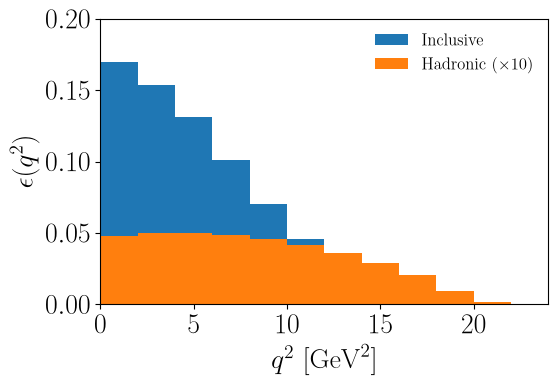

In [2]:
eff = interp1d(eff_bin_cents, eff_vals, kind = 3, fill_value = "extrapolate")
effHad = interp1d(eff_bin_cents, effHad_vals, kind = 3, fill_value = "extrapolate")

fig, axes = plt.subplots(nrows=1, ncols=1)

tot1 = axes.stairs(eff_vals, eff_bins, fill=True)
tot2 = axes.stairs(10*effHad_vals, eff_bins, fill=True)

qsq_vals = np.linspace(0, (mB - mK)**2, 200)
eff_vals_plot = eff(qsq_vals)
effHad_vals_plot = effHad(qsq_vals)

axes.set_xlim(0,24);
axes.set_ylim(0,0.20);
axes.set_xlabel(r'$q^2~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$\epsilon(q^2)$');

leg1 = axes.legend([tot1, tot2], [r'Inclusive', r'Hadronic ($\times 10$)'], loc='upper right', fontsize=12, frameon=False)

plt.subplots_adjust(left=0.2)
plt.subplots_adjust(bottom=0.2)
fig.set_size_inches(6.4, 4.2)

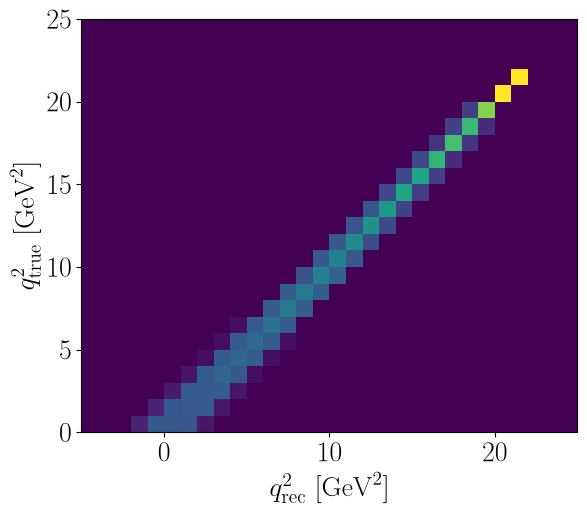

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=1)

axes.imshow(smearing_data, extent = (-5, 25, 25, -5));

axes.set_xlim(-5,25);
axes.set_ylim(0,25);
axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$q^2_{\mathrm{true}}~[\mathrm{GeV}^2]$');

fig.set_size_inches(6.4, 9.6)

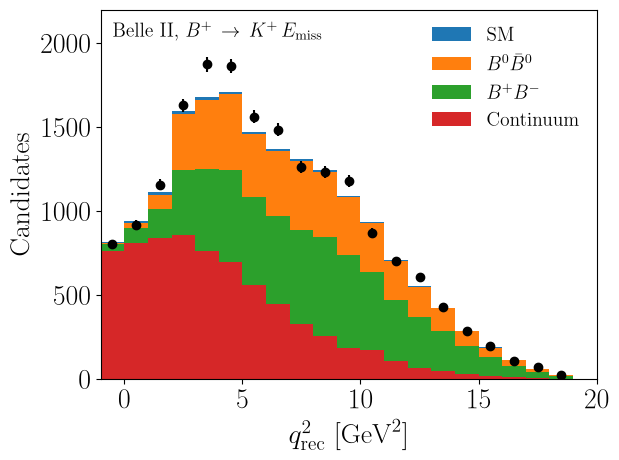

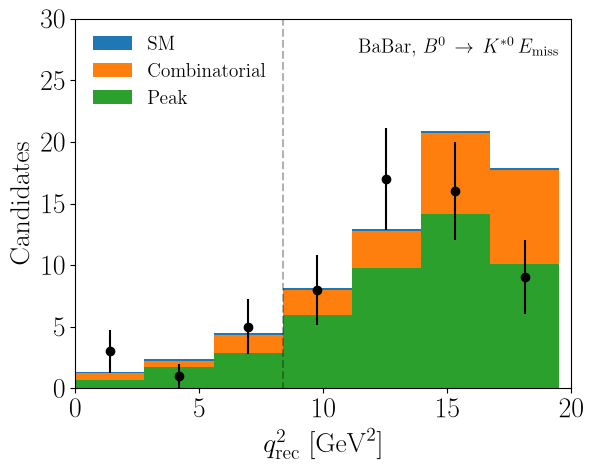

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=1)

tot1 = plt.stairs(s_SM_BelleII + b_cont + b_charged + b_neutral, bins, fill=True)
tot2 = plt.stairs(b_cont + b_charged + b_neutral, bins, fill=True)
tot3 = plt.stairs(b_cont + b_charged, bins, fill=True)
tot4 = plt.stairs(b_cont, bins, fill=True)

plt.errorbar(bin_cents, obs, fmt='ok', yerr=np.sqrt(obs))
axes.set_xlim(-1,20);
axes.set_ylim(0,2200);
axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$\mathrm{Candidates}$');

axes.legend([tot1,tot2,tot3,tot4], [r'SM', r'$B^0\bar{B}^0$', r'$B^+B^-$', r'Continuum'], loc='upper right',fontsize=14,frameon=False)

axes.text(-0.5,2040, r'Belle~II,~$B^+\,\to \,K^+\,E_{\mathrm{miss}}$', fontsize=14);
fig.set_size_inches(6.4, 4.8)

fig, axes = plt.subplots(nrows=1, ncols=1)

tot1 = plt.stairs(s_SM_BaBar + b_BaBar_peak_K0 + b_BaBar_comb_K0, bins_BaBar * mB**2, fill=True)
tot2 = plt.stairs(b_BaBar_peak_K0 + b_BaBar_comb_K0, bins_BaBar * mB**2, fill=True)
tot3 = plt.stairs(b_BaBar_peak_K0, bins_BaBar * mB**2, fill=True)

axes.plot([0.3 * mB**2, 0.3 * mB**2],[-1,31],color='k',ls='--',alpha=0.3)

plt.errorbar(bin_cents_BaBar * mB**2, obs_BaBar_K0, fmt='ok', yerr=np.sqrt(obs_BaBar_K0))
axes.set_xlim(0,20);
axes.set_ylim(0,30);
axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$\mathrm{Candidates}$');

axes.legend([tot1,tot2,tot3], [r'SM', r'Combinatorial', r'Peak'], loc='upper left',fontsize=14,frameon=False)

axes.text(11.4,27.25, r'BaBar,~$B^0\,\to \,K^{*0} \, E_{\mathrm{miss}}$', fontsize=14);
fig.set_size_inches(6.4, 4.8)

In [5]:
from lights.likelihoods import Nevents_BelleII, logLL_BelleII, min_logLL, profile_logLL_SM
from lights.statistics import reduced_chisq

mu_val, mu_err, m_BelleII, mu_min = min_logLL(logLL_BelleII, Nrec_BelleII)
mu_val, mu_err, mu_min

(5.086475691062792, 1.5886722372786655, -6.693110674794298)

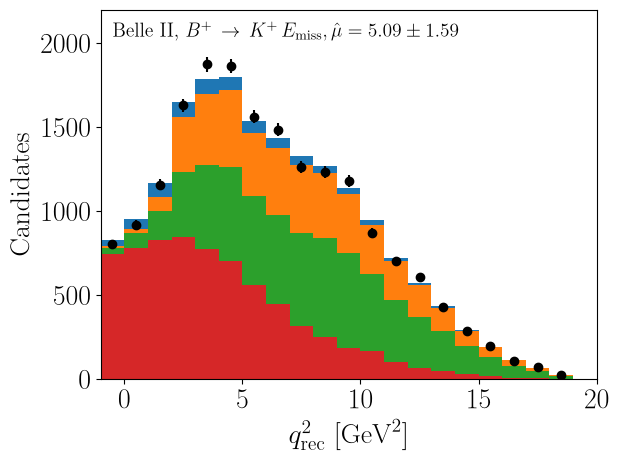

In [6]:
from lights.likelihoods import components_BelleII

# Fitted signal and background components per bin (includes the fitted nuisance parameters)
comp = components_BelleII(m_BelleII.values)

s_SM_fit = comp["SM"]
b_cont_fit = comp["cont"]
b_charged_fit = comp["charged"]
b_neutral_fit = comp["neutral"]

fig, axes = plt.subplots(nrows=1, ncols=1)

plt.stairs(s_SM_fit + b_cont_fit + b_charged_fit + b_neutral_fit, bins, fill=True)
plt.stairs(b_cont_fit + b_charged_fit + b_neutral_fit, bins, fill=True)
plt.stairs(b_cont_fit + b_charged_fit, bins, fill=True)
plt.stairs(b_cont_fit, bins, fill=True)

plt.errorbar(bin_cents, obs, fmt='ok', yerr=np.sqrt(obs))
axes.set_xlim(-1,20);
axes.set_ylim(0,2200);
axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$\mathrm{Candidates}$');

axes.text(-0.5,2040, r'Belle~II,~$B^+\,\to \,K^+\,E_{\mathrm{miss}}, \hat{\mu} = %1.2f \pm %1.2f $' % (mu_val, mu_err), fontsize=14);

In [7]:
chisq_inc = reduced_chisq(m_BelleII, obs)
print(chisq_inc)

1.9806220829057948


In [8]:
px_inc_profile = np.linspace(0.,8,50)
py_inc_profile = []
for i in range(len(px_inc_profile)):
    py_inc_profile.append(profile_logLL_SM(logLL_BelleII, px_inc_profile[i]))

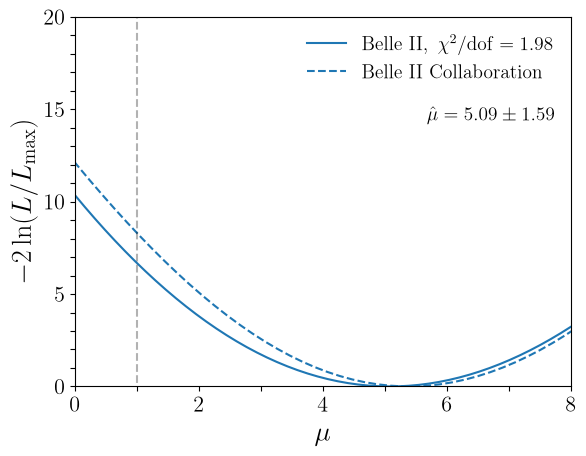

In [9]:
# Compare log likelihoods

cmap = plt.get_cmap("tab10")

fig, axes = plt.subplots(nrows=1, ncols=1)

tot1, = axes.plot(px_inc_profile, py_inc_profile, color=cmap(0), ls = '-');
tot2, = axes.plot(np.array(pd.io.json.read_json(DATA_DIR / "ITALikelihoodPoints_PDF.json"))[::,0],np.array(pd.io.json.read_json(DATA_DIR / "ITALikelihoodPoints_PDF.json"))[::,1], color=cmap(0), ls = '--');

axes.plot([1,1],[-1,81],color='k',ls='--',alpha=0.3)

axes.set_xticks([0,1,2,3,4,5,6,7,8])
axes.xaxis.set_ticklabels([r'$0$',r'',r'$2$',r'',r'$4$',r'',r'$6$',r'',r'$8$'],fontsize = 16)
axes.set_yticks([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20])
axes.yaxis.set_ticklabels([r'$0$',r'',r'',r'',r'',r'$5$',r'',r'',r'',r'',r'$10$',r'',r'',r'',r'',r'$15$',r'',r'',r'',r'',r'$20$'],fontsize = 16)

axes.set_xlim(0,8)
axes.set_ylim(0,20)
axes.set_xlabel(r'$\mu$');
axes.set_ylabel(r'$-2\ln(L/L_\mathrm{max})$');

axes.text(5.68, 14.4, r'$\hat{\mu} = %1.2f \pm %1.2f $' % (mu_val, mu_err), fontsize=14)

leg1 = axes.legend([tot1,tot2], [r'Belle II, $\,\chi^2/\mathrm{dof} = %1.2f$ ' % chisq_inc, r'Belle II Collaboration'], loc='upper right', fontsize=14, frameon=False)

fig.set_size_inches(6.4, 4.8)